## Statistics and data

Descriptive statistics on a small data set: what MATLAB's reductions compute, how they treat missing values (`NaN`), and two plots.

In [ ]:
scores = [12.5 18.2 14.1 22.0 19.8 14.1 16.5 21.3 15.7 17.9];
fprintf('n = %d\n', numel(scores))
fprintf('mean %.3f, median %.3f, mode %.1f\n', mean(scores), median(scores), mode(scores))
fprintf('variance %.3f, standard deviation %.3f\n', var(scores), std(scores))
quartiles = prctile(scores, [25 50 75])
spread = [min(scores) max(scores)]

n = 10


mean 17.210, median 17.200, mode 14.1
variance 10.239, standard deviation 3.200

quartiles =

   14.1000   17.2000   19.8000


spread =

   12.5000   22.0000



### z-scores

A z-score says how many standard deviations a value is from the mean: $z_i = (x_i - \bar x)/s$. The z-scores have mean 0 and standard deviation 1.

In [ ]:
z = (scores - mean(scores)) / std(scores);
disp(round(z, 3))
fprintf('mean %.2g, std %.4f\n', mean(z), std(z))

  Columns 1 through 7

   -1.4720    0.3090   -0.9720    1.4970    0.8090   -0.9720   -0.2220

  Columns 8 through 10

    1.2780   -0.4720    0.2160
mean -3.2e-16, std 1.0000


### Missing values

`NaN` marks a missing value. By default it propagates, so the mean of data with a gap is `NaN`; `'omitnan'` leaves the gaps out.

In [ ]:
daily = [10 NaN 20 30 NaN 25 15];
mean(daily)
mean(daily, 'omitnan')
median(daily, 'omitnan')
missing = sum(isnan(daily))


ans =

   NaN


ans =

    20


ans =

    20


missing =

     2



### Moving windows and running extremes

The spike at the third sample pulls the moving mean up; the moving median ignores it.

In [ ]:
signal = [1 2 10 4 5 6 7 3 2 8];
smooth = movmean(signal, 3)
robust = movmedian(signal, 3)
highest_so_far = cummax(signal)


smooth =

  Columns 1 through 7

    1.5000    4.3333    5.3333    6.3333    5.0000    6.0000    5.3333

  Columns 8 through 10

    4.0000    4.3333    5.0000


robust =

  Columns 1 through 7

    1.5000    2.0000    4.0000    5.0000    5.0000    6.0000    6.0000

  Columns 8 through 10

    3.0000    3.0000    5.0000


highest_so_far =

     1     2    10    10    10    10    10    10    10    10



### A histogram

A thousand normally distributed values (`randn`), counted in bins; `rng` makes the sample the same every run.


counts =

    94   413   377   102



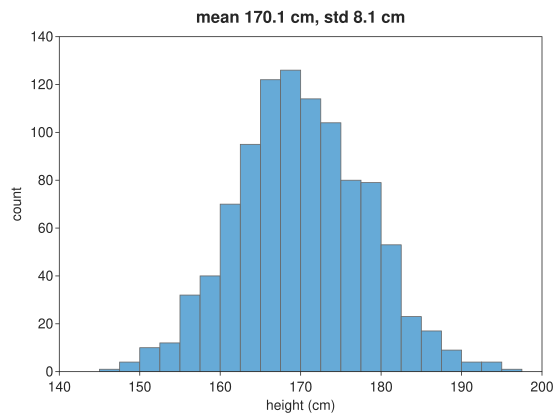

In [ ]:
figure
rng(7);
heights = 170 + 8 * randn(1000, 1);
histogram(heights, 140:2.5:200)
xlabel('height (cm)'), ylabel('count')
title(sprintf('mean %.1f cm, std %.1f cm', mean(heights), std(heights)))
counts = histcounts(heights, [150 160 170 180 190])

### Correlation and a fitted line

`corrcoef` gives the correlation matrix; `polyfit` fits a polynomial by least squares, here a line, and `polyval` evaluates it.

correlation 0.957


grade = 4.16 * hours + 51.51


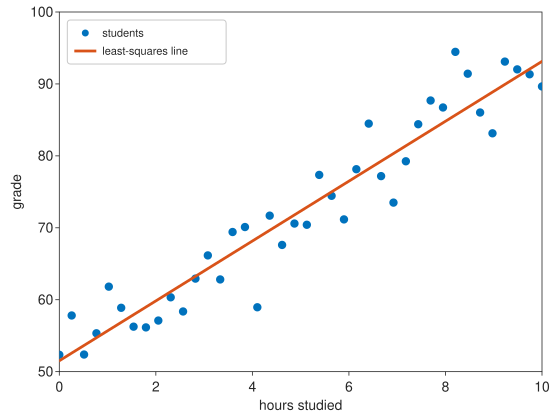

In [ ]:
figure
rng(3);
hours = linspace(0, 10, 40)';
grade = 52 + 4.1 * hours + 5 * randn(40, 1);
C = corrcoef(hours, grade);
fprintf('correlation %.3f\n', C(1, 2))
p = polyfit(hours, grade, 1);
fprintf('grade = %.2f * hours + %.2f\n', p(1), p(2))
plot(hours, grade, 'o', hours, polyval(p, hours), '-', 'LineWidth', 1.5)
xlabel('hours studied'), ylabel('grade')
legend('students', 'least-squares line', 'Location', 'northwest')

### Sorting rows and unique values

In [ ]:
T = [3 20; 1 40; 3 10; 2 50];
sortrows(T, [1 -2])
[vals, ~, idx] = unique([5 2 8 2 5 1]);
vals
counts_each = accumarray(idx(:), 1)'


ans =

     1    40
     2    50
     3    20
     3    10


vals =

     1     2     5     8


counts_each =

     1     2     2     1



*Topics after examples in MatRust-Studio (MIT license); the code here is Sagebrush's own.*